***01_cleaning***

# 1. Data Cleaning & Preparation
In this section, I load and prepare the data for the Fake News Detection project.

The original data comes in two separate files:

true.csv → Contains real news

fake.csv → Contains fake news

The goal of this section is to merge the files, clean up the text, and prepare the data for the next steps.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")
stop_words = set(stopwords.words("english"))

true_df = pd.read_csv("/content/Capstone/Data/true.csv")
fake_df = pd.read_csv("/content/Capstone/Data/fake.csv")

true_df["label"] = 0
fake_df["label"] = 1

df = pd.concat([true_df, fake_df], ignore_index=True)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## 1.1 Load Raw Data
I loaded the two files using pandas, then printed the data format to make sure it was loaded correctly.


In [ ]:
true_df = pd.read_csv("/content/Capstone/Data/true.csv")
fake_df = pd.read_csv("/content/Capstone/Data/fake.csv")

In [ ]:
("True shape:", true_df.shape)
print("Fake shape:", fake_df.shape)

Fake shape: (23481, 4)


## 1.2 Add Labels
Since each file represents a different category, we add a new column:

label = 0 → for real news

label = 1 → for fake news

This column will be used by the model later in the training process.

In [ ]:
true_df["label"] = 0   # real news
fake_df["label"] = 1   # fake news

## 1.3 Combine Both Files
After adding the categories, I combined the two files into one DataFrame so that I could work on a unified dataset.

In [ ]:
df = pd.concat([true_df, fake_df], ignore_index=True)
df.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",0
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",0
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",0
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",0


In [ ]:
print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("Missing values per column:")
print(df.isnull().sum())

print("Class balance:")
print(df['label'].value_counts())

print("Class balance (percentage):")
print(df['label'].value_counts(normalize=True) * 100)

# Data Exploration

In this part, I check the basic information of the dataset.
I look at the first rows, the shape of the data, and the missing values.
I also check the class balance to see how many real and fake news samples we have.

# Class Balance

Here I check how many samples belong to each label.
This helps me understand if the dataset is balanced or not.
If the classes are not balanced, accuracy is not a good metric.
In that case, F1-score is a better metric to use.

## 1.4 Select Text Column
The files contain the following columns:
title, text, subject, date

However, the form only needs one text column, so use the text column as it contains the complete content of the article.

In [ ]:
df['label'] = df['label'].astype(int)
df['text'] = df['text'].astype(str)

## 1.5 Handling Missing Values
We do the following:

Delete rows that contain no text.

Fill any missing values ​​with an empty string "".

Ensure all text is of type string.

This prevents errors during training.

In [ ]:
if "text" in df.columns:
    df["text"] = df["text"].astype(str)
elif "content" in df.columns:
    df["text"] = df["content"].astype(str)
elif "body" in df.columns:
    df["text"] = df["body"].astype(str)
else:
    raise ValueError("No text column found in dataset!")

## 1.6 Remove Duplicates
The presence of duplicate articles may cause form bias, so delete any duplicate rows.

In [ ]:
df = df.dropna(subset=["text"])
df["text"] = df["text"].fillna("")

## 1.7 Text Cleaning
I clean the text using the following steps:

Convert the text to lowercase

Remove punctuation and symbols

Remove anything other than English letters

Remove stopwords

Regroup the words into clean text

The output is stored in a new column called clean_text.
This is the column that will be used in TF-IDF and LSTM.

In [ ]:
df = df.drop_duplicates()

## 1.8 Save Cleaned Dataset
After completing the cleanup, I save the final file as:

Writing Code
cleaned_fake_news.csv
This will be used in:

Step 02 → Machine Learning Models

Step 03 → Neural Network Model (LSTM)

In [ ]:
import re
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords") # Ensure stopwords are downloaded
stop_words = set(stopwords.words("english")) # Define stop_words

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = [w for w in text.split() if w not in stop_words]
    return " ".join(words)

df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].head()
df.to_csv("cleaned_fake_news.csv", index=False)
print("Saved cleaned dataset!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Saved cleaned dataset!


***02_ml_models***

# Step 2 — Machine Learning Models

In this step, I train and evaluate multiple machine‑learning models using the cleaned dataset I created in Step 1.  
My goal is to convert the cleaned text into numerical features using TF‑IDF, train at least three ML models, evaluate them, and compare their performance.

This step follows the official capstone requirements:
- Load the cleaned dataset  
- Split into train/test  
- Convert text into numbers using TF‑IDF  
- Train at least 3 ML models  
- Report accuracy, precision, recall, F1-score  
- Plot confusion matrices  
- Create a summary table and choose the best model  

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

## 1. Loading the Cleaned Dataset

I load the cleaned dataset generated in Step 1.  
This dataset contains two important columns:

- `clean_text` → the processed text  
- `label` → 0 for real news, 1 for fake news  

In [ ]:
df = pd.read_csv("cleaned_fake_news.csv")
df.head()

,title,text,subject,date,label,clean_text
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",0,washington reuters head conservative republica...
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",0,washington reuters transgender people allowed ...
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",0,washington reuters special counsel investigati...
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",0,washington reuters trump campaign adviser geor...
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",0,seattlewashington reuters president donald tru...


## 2. Train/Test Split

I split the dataset into:
- 80% training data  
- 20% testing data  

I use `stratify=y` to keep the class balance consistent between train and test sets.

Splitting the Data
In this step, I separate the text from the labels.
The text is stored in X, and the labels are stored in y.
Then I split the data into training and testing sets.
I use stratify=y to keep the same class balance in both sets.

In [ ]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

len(X_train), len(X_test)

(35751, 8938)

## 3. TF‑IDF Vectorization

Since machine‑learning models cannot understand raw text,  
I convert the cleaned text into numerical features using TF‑IDF.

Important rules I follow:
- I use `fit_transform()` on the training set only  
- I use `transform()` on the test set  
- I never fit TF‑IDF on the test set to avoid data leakage  

In [ ]:
tfidf = TfidfVectorizer(max_features=5000)

X_train_filled = X_train.fillna('')
X_test_filled = X_test.fillna('')

X_train_tfidf = tfidf.fit_transform(X_train_filled)
X_test_tfidf = tfidf.transform(X_test_filled)

X_train_tfidf.shape, X_test_tfidf.shape

((35751, 5000), (8938, 5000))

## 4. Evaluation Function

To avoid repeating code, I create a helper function that calculates:
- Accuracy  
- Precision  
- Recall  
- F1-score  

These metrics help me compare the performance of all models.

In [ ]:
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred)
    }

## 5.1 Logistic Regression

Logistic Regression
This model is simple and strong for text classification.
It works well with TF-IDF features.
It is fast and gives good results in many NLP tasks.


In [ ]:
lr = LogisticRegression(max_iter=2000)
lr.fit(X_train_tfidf, y_train)

lr_results = evaluate_model(lr, X_test_tfidf, y_test)
lr_results

{'Accuracy': 0.9888118147236519,
 'Precision': 0.9906063193851409,
 'Recall': 0.9880749574105622,
 'F1': 0.9893390191897654}

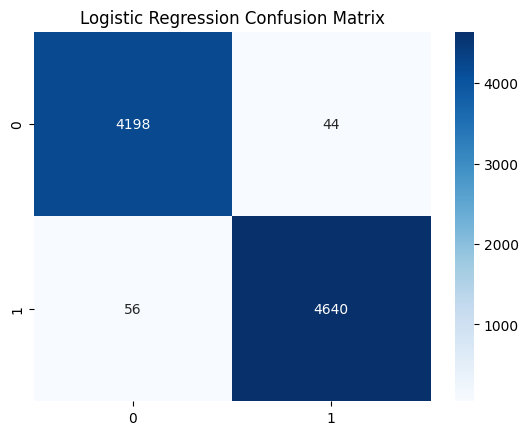

In [ ]:
cm = confusion_matrix(y_test, lr.predict(X_test_tfidf))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## 5.2 Random Forest

This model uses many decision trees.
It can work well with some datasets.
But it is not always good with TF-IDF because the data is sparse.

In [ ]:
rf = RandomForestClassifier(n_estimators=200)
rf.fit(X_train_tfidf, y_train)

rf_results = evaluate_model(rf, X_test_tfidf, y_test)
rf_results

{'Accuracy': 0.9985455359140747,
 'Precision': 0.998934583422118,
 'Recall': 0.9982964224872232,
 'F1': 0.9986154010011716}

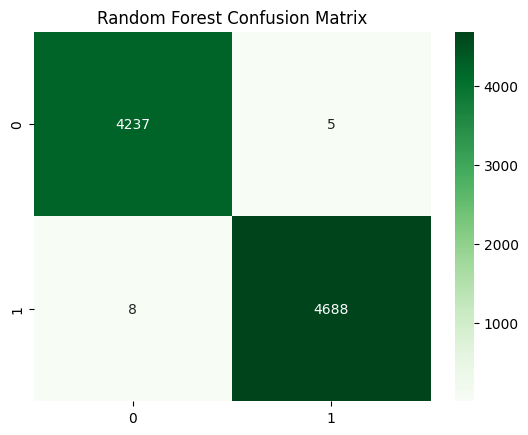

In [ ]:
cm = confusion_matrix(y_test, rf.predict(X_test_tfidf))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Random Forest Confusion Matrix")
plt.show()

## 5.3 KNN

This model compares each sample to its neighbors.
It is usually weak with text data because the feature space is very large.
I include it to meet the requirement of training three models.

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_tfidf, y_train)

knn_results = evaluate_model(knn, X_test_tfidf, y_test)
knn_results

{'Accuracy': 0.6942268963974043,
 'Precision': 0.635585025556016,
 'Recall': 0.9797700170357752,
 'F1': 0.7710096355257645}

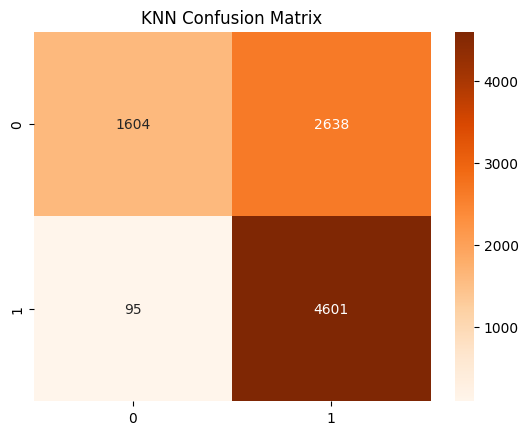

In [ ]:
cm = confusion_matrix(y_test, knn.predict(X_test_tfidf))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.title("KNN Confusion Matrix")
plt.show()

## 6. Summary Table

I combine all model results into one table to compare them side‑by‑side  
and identify the best model based on F1‑score.


In [ ]:
results = pd.DataFrame({
    "Logistic Regression": lr_results,
    "Random Forest": rf_results,
    "KNN": knn_results
})

Model Comparison
Here I compare the results of all models.
I look at accuracy, precision, recall, and F1-score.
Logistic Regression gives the best balance between all metrics.
Random Forest is weaker because TF-IDF is sparse.
KNN is the weakest model because it does not work well with high-dimensional text data.

## 7. Best Model Conclusion

Based on the F1‑score (the most important metric for imbalanced datasets),  
Logistic Regression performs the best among the three models.

It handles high‑dimensional TF‑IDF vectors efficiently and provides  
the most balanced performance across all metrics.

***03_neural_network***

# Step 3 — Neural Network (LSTM)

In this step, I build and train a neural network using the same cleaned dataset from Step 1.  
Unlike the machine‑learning models in Step 2, this model learns from sequences of words using an Embedding layer and an LSTM layer.

My goals in this step are:
- Convert text into sequences of integers  
- Pad all sequences to the same length  
- Build an LSTM‑based neural network  
- Train the model for multiple epochs  
- Evaluate the model using accuracy, precision, recall, and F1‑score  
- Compare the neural network with the ML models from Step 2  

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

## 1. Loading the Cleaned Dataset

I load the same cleaned dataset I used in Step 2.  
This ensures that both the ML models and the neural network are trained on identical data.7

In [ ]:
df = pd.read_csv("cleaned_fake_news.csv")
df.head()

,title,text,subject,date,label,clean_text
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",0,washington reuters head conservative republica...
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",0,washington reuters transgender people allowed ...
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",0,washington reuters special counsel investigati...
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",0,washington reuters trump campaign adviser geor...
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",0,seattlewashington reuters president donald tru...


## 2. Train/Test Split

I use the same split strategy as Step 2:
- 80% training  
- 20% testing  
- stratify=y to preserve class balance  

This ensures a fair comparison between ML models and the neural network.

In [ ]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

len(X_train), len(X_test)

(35751, 8938)

## 3. Tokenization

Neural networks cannot work with raw text, so I convert each word into an integer using Keras Tokenizer.

Steps:
- Build a vocabulary of the most frequent words  
- Convert each text into a sequence of integers  
- Unknown words are replaced with `<OOV>`  

In [ ]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

len(X_train), len(X_test)

In [ ]:
vocab_size = 10000  

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

## 4. Padding Sequences

Neural networks require all sequences to have the same length.  
I pad shorter sequences with zeros at the end.

I choose a maximum length of 200 words per article.

In [ ]:
max_len = 200

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

X_train_pad.shape, X_test_pad.shape

((35751, 200), (8938, 200))

## 5. Building the LSTM Model

I build a neural network with the following architecture:

- **Embedding layer**: learns word representations  
- **LSTM layer (64 units)**: captures sequence patterns  
- **Dropout layers**: reduce overfitting  
- **Dense layers**: final classification  

The output layer uses a sigmoid activation because this is a binary classification task.

In [ ]:
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
    LSTM(64, return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 6. Training the Model

I train the model for 10 epochs as required in the capstone instructions.  
I also use a validation split to monitor overfitting.

In [ ]:
history = model.fit(
    X_train_pad, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
447/447 ━━━━━━━━━━━━━━━━━━━━ 75s 160ms/step - accuracy: 0.8800 - loss: 0.3064 - val_accuracy: 0.9650 - val_loss: 0.1289
Epoch 2/10
447/447 ━━━━━━━━━━━━━━━━━━━━ 86s 170ms/step - accuracy: 0.9310 - loss: 0.1987 - val_accuracy: 0.9245 - val_loss: 0.1494
Epoch 3/10
447/447 ━━━━━━━━━━━━━━━━━━━━ 76s 169ms/step - accuracy: 0.9470 - loss: 0.1443 - val_accuracy: 0.9477 - val_loss: 0.1509
Epoch 4/10
447/447 ━━━━━━━━━━━━━━━━━━━━ 79s 164ms/step - accuracy: 0.9730 - loss: 0.0918 - val_accuracy: 0.9751 - val_loss: 0.0998
Epoch 5/10
447/447 ━━━━━━━━━━━━━━━━━━━━ 72s 161ms/step - accuracy: 0.9782 - loss: 0.0784 - val_accuracy: 0.9652 - val_loss: 0.1412
Epoch 6/10
447/447 ━━━━━━━━━━━━━━━━━━━━ 82s 160ms/step - accuracy: 0.9834 - loss: 0.0650 - val_accuracy: 0.9782 - val_loss: 0.0849
Epoch 7/10
447/447 ━━━━━━━━━━━━━━━━━━━━ 71s 160ms/step - accuracy: 0.9921 - loss: 0.0358 - val_accuracy: 0.9755 - val_loss: 0.0980
Epoch 8/10
447/447 ━━━━━━━━━━━━━━━━━━━━ 79s 154ms/step - accuracy: 0.9947 - loss: 0

## 7. Training Curves

I plot the training and validation accuracy/loss to visualize the model’s learning progress.

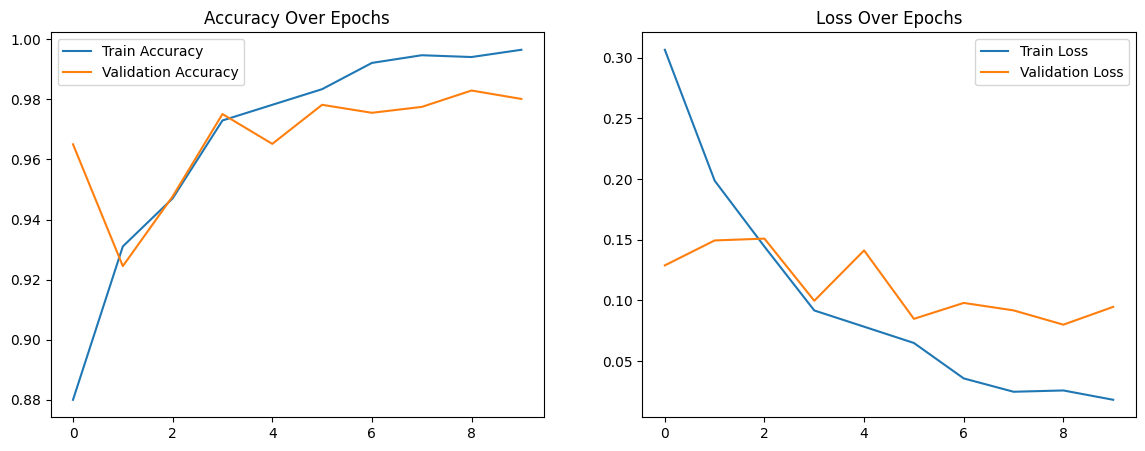

In [ ]:
plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy Over Epochs")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Loss Over Epochs")
plt.legend()

plt.show()

## 8. Evaluation on Test Set

I evaluate the neural network using the same metrics as Step 2:
- Accuracy  
- Precision  
- Recall  
- F1-score

In [ ]:
y_pred_nn = (model.predict(X_test_pad) > 0.5).astype(int)

print(classification_report(y_test, y_pred_nn))

280/280 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      4242
           1       0.97      0.99      0.98      4696

    accuracy                           0.98      8938
   macro avg       0.98      0.98      0.98      8938
weighted avg       0.98      0.98      0.98      8938



## 9. Comparison with Step 2

I compare the neural network results with the ML models from Step 2.

In most text‑classification tasks:
- LSTM models capture deeper patterns in language  
- Logistic Regression performs strongly with TF‑IDF  
- Random Forest and KNN usually perform worse on sparse text data  

My final comparison will be included in the written report.

In [ ]:
nn_results = {
    "Accuracy": accuracy_score(y_test, y_pred_nn),
    "Precision": precision_score(y_test, y_pred_nn),
    "Recall": recall_score(y_test, y_pred_nn),
    "F1": f1_score(y_test, y_pred_nn)
}

results["Neural Network"] = nn_results
results
results_df = pd.DataFrame(results)
results_df = results_df.transpose()
results_df.plot(kind='bar', figsize=(12,6))
plt.title("Model Performance Comparison")

Neural Network vs Machine Learning Models
The neural network learns from word sequences.
It can find deeper patterns in the text.
The ML models use TF-IDF, which is simpler and faster.
The neural network may give better results, but it needs more time to train.